## Southern Langeland bend manoeuvring (Flag 25)

### Dataset Overview
Constructed cargo and tanker passages around southern Langeland and into Langelandsbælt, with recurring waterborne turning patterns, phase-dependent speeds, and probabilistic draught-related use of the DW Route Langelandsbaelt.

The notebook exposes a primary table and a supporting table (`vessels.csv`).

Goal: Analyze how vessels navigate the major bend around southern Langeland in Langelandsbælt, in the southern Great Belt, and identify recurring movement patterns and differences in manoeuvring behaviour.

Role: Maritime traffic analyst


Category: southern langeland bend manoeuvring

### Your Objective
Use the provided tables and visual evidence to answer the questions below and summarize the observed trajectory patterns.


## Import Necessary Libraries

This cell loads the data-analysis and visualization libraries used by the questions below.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, SVG, display

## Load Dataset

The primary table is loaded into `df`; when available, the supporting trajectory or driver table is loaded into `user_df`.

In [ ]:
dataset_path = "trajectory_points.csv"
import pandas as pd
import matplotlib.pyplot as plt
df = pd.read_csv(dataset_path)

In [ ]:
user_dataset_path = "vessels.csv"
user_df = pd.read_csv(user_dataset_path)

### **Question 1**: Which recurring turning mechanisms organize traffic through the bend?

#### Analysis action

Compare the early/tight, DW-route, and late/wide manoeuvring geometries.

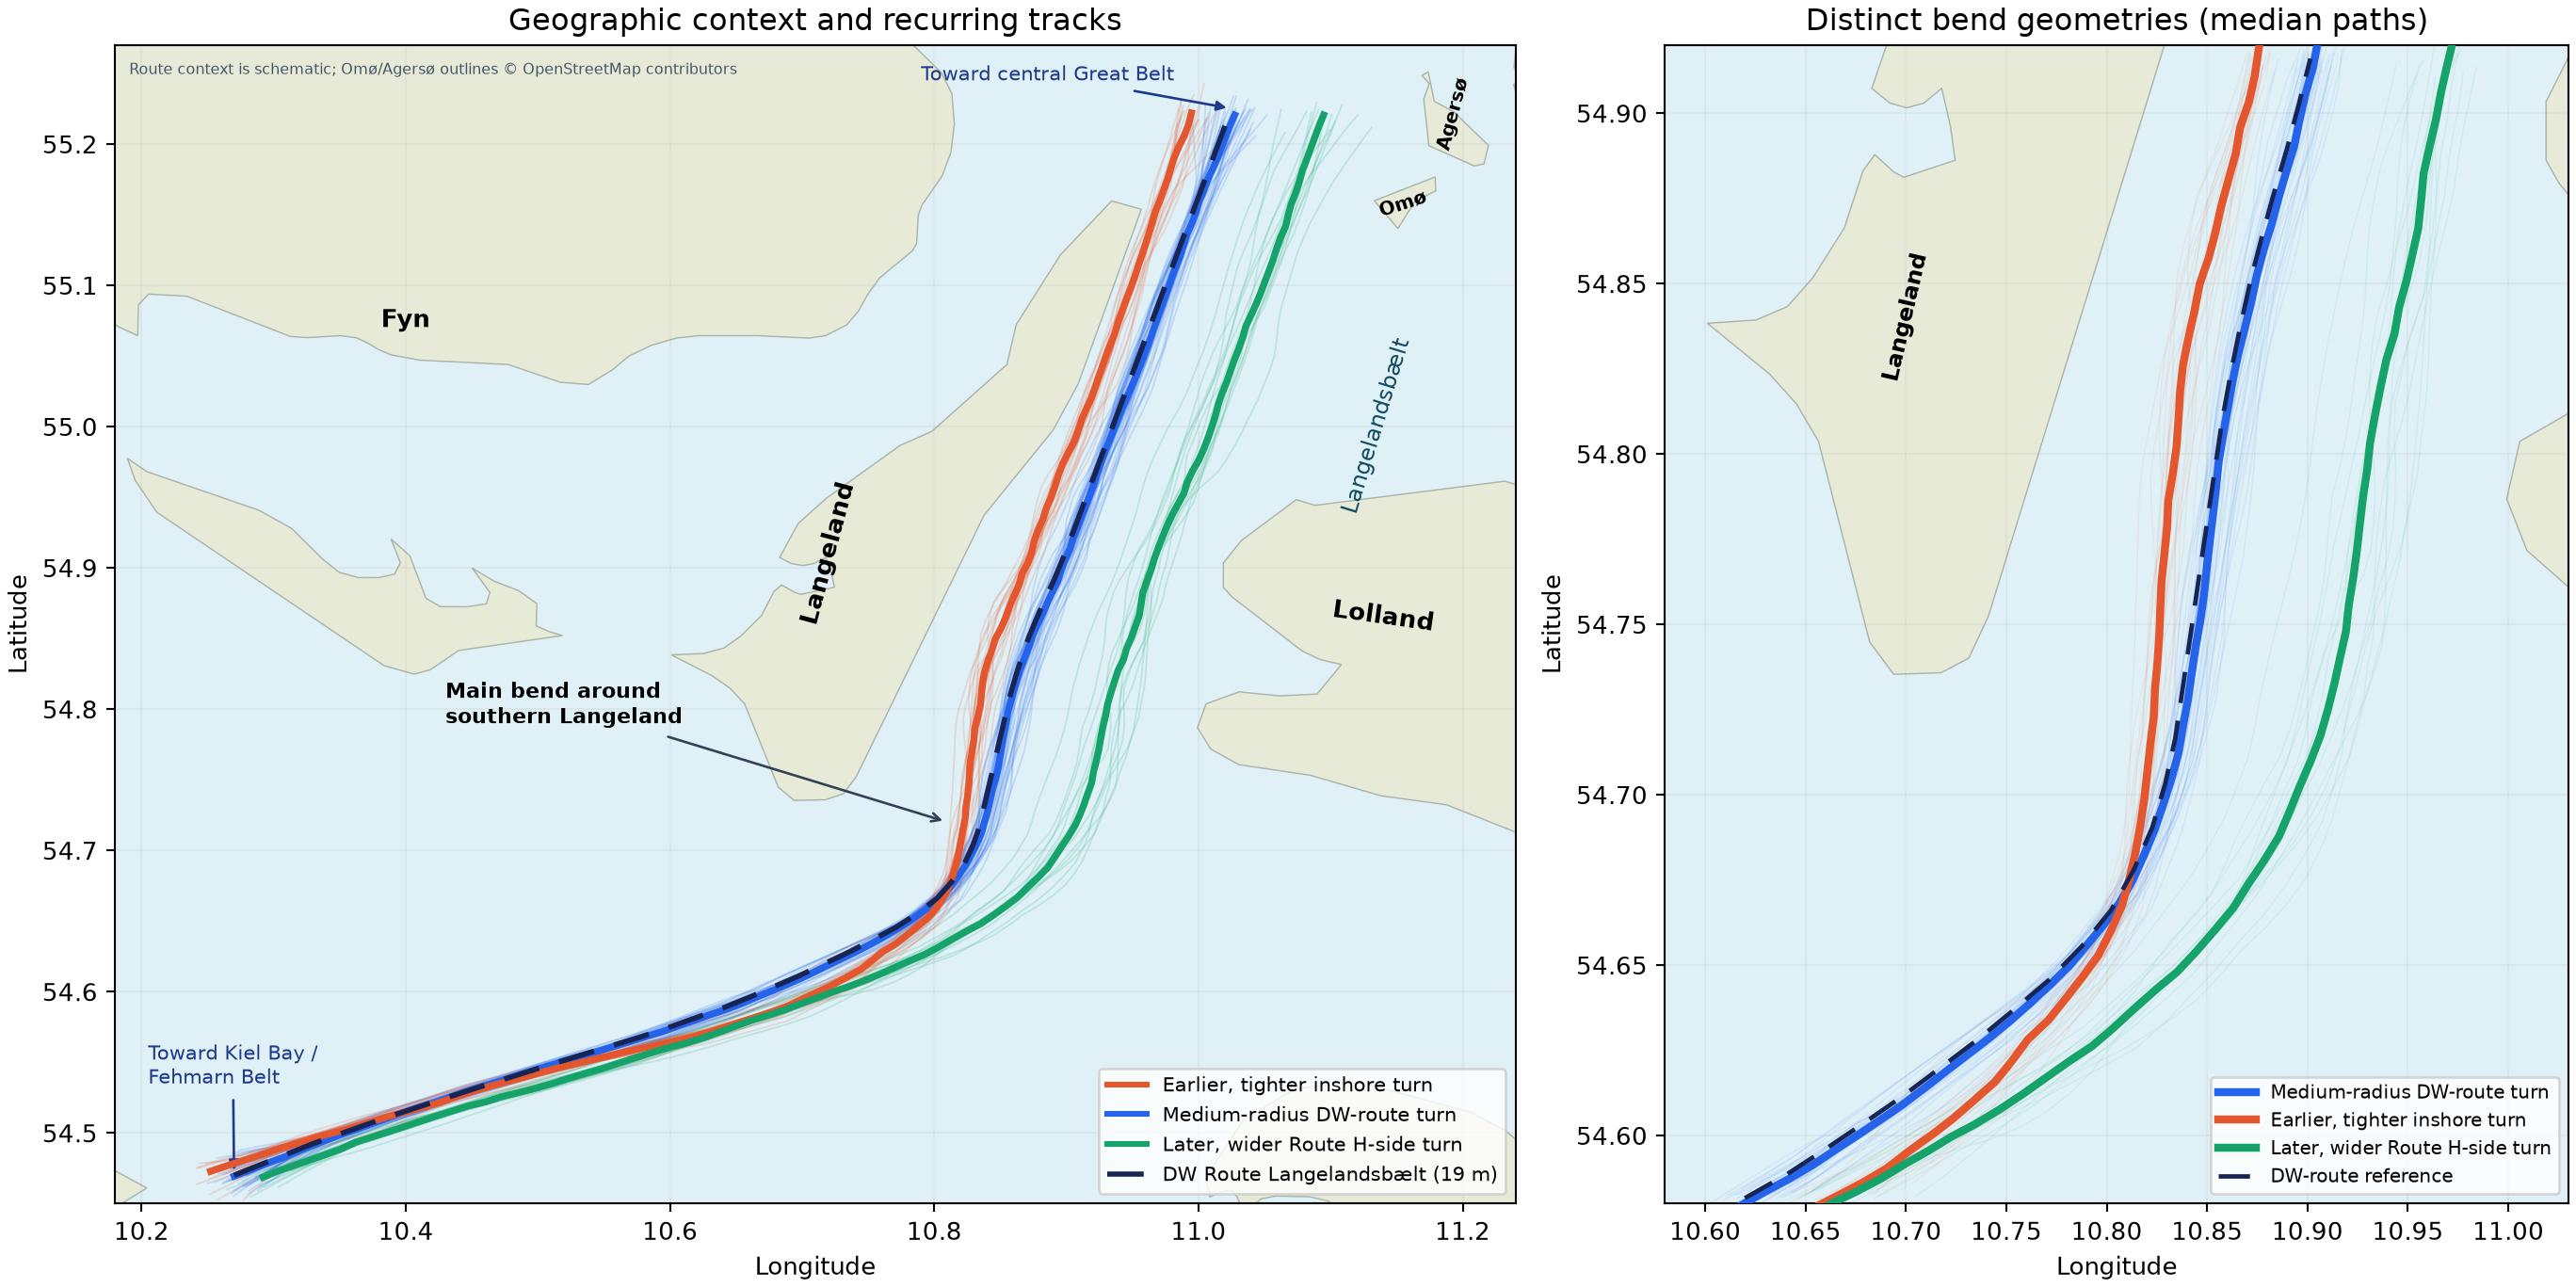

In [ ]:
import pandas as pd
df=pd.read_csv(dataset_path); print(df.groupby('turning_pattern').trajectory_id.nunique())
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/recurring_turning_patterns.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Low (3 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "recurring_bend_patterns",
  "insight": "Traffic around southern Langeland forms three recurring manoeuvring patterns: an earlier tighter inshore turn, a consistent medium-radius DW-route turn, and a later wider turn on the Route H side.",
  "insight_value": {
    "turning_pattern_counts": {
      "deep_water": 40,
      "early_tight": 21,
      "late_wide": 15
    }
  },
  "plot": {
    "plot_type": "pattern_colored_map",
    "title": "Recurring Turning Patterns around Southern Langeland",
    "file": "visualizations/recurring_turning_patterns.png",
    "description": "Compare the early/tight, DW-route, and late/wide manoeuvring geometries."
  },
  "question": "Which recurring turning mechanisms organize traffic through the bend?",
  "actionable_insight": "Compare the early/tight, DW-route, and late/wide manoeuvring geometries.",
  "code": "import pandas as pd\ndf=pd.read_csv(dataset_path); print(df.groupby('turning_pattern').trajectory_id.nunique())",
  "insight_type": "overall_pattern",
  "difficulty_level": 3,
  "difficulty_label": "low",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "gps_position",
    "route_reference",
    "vessel_id"
  ]
}

### **Question 2**: How does speed change before, during, and after the main turn?

#### Analysis action

Align vessel speed and COG change across approach, reduction, main-turn, and recovery phases.

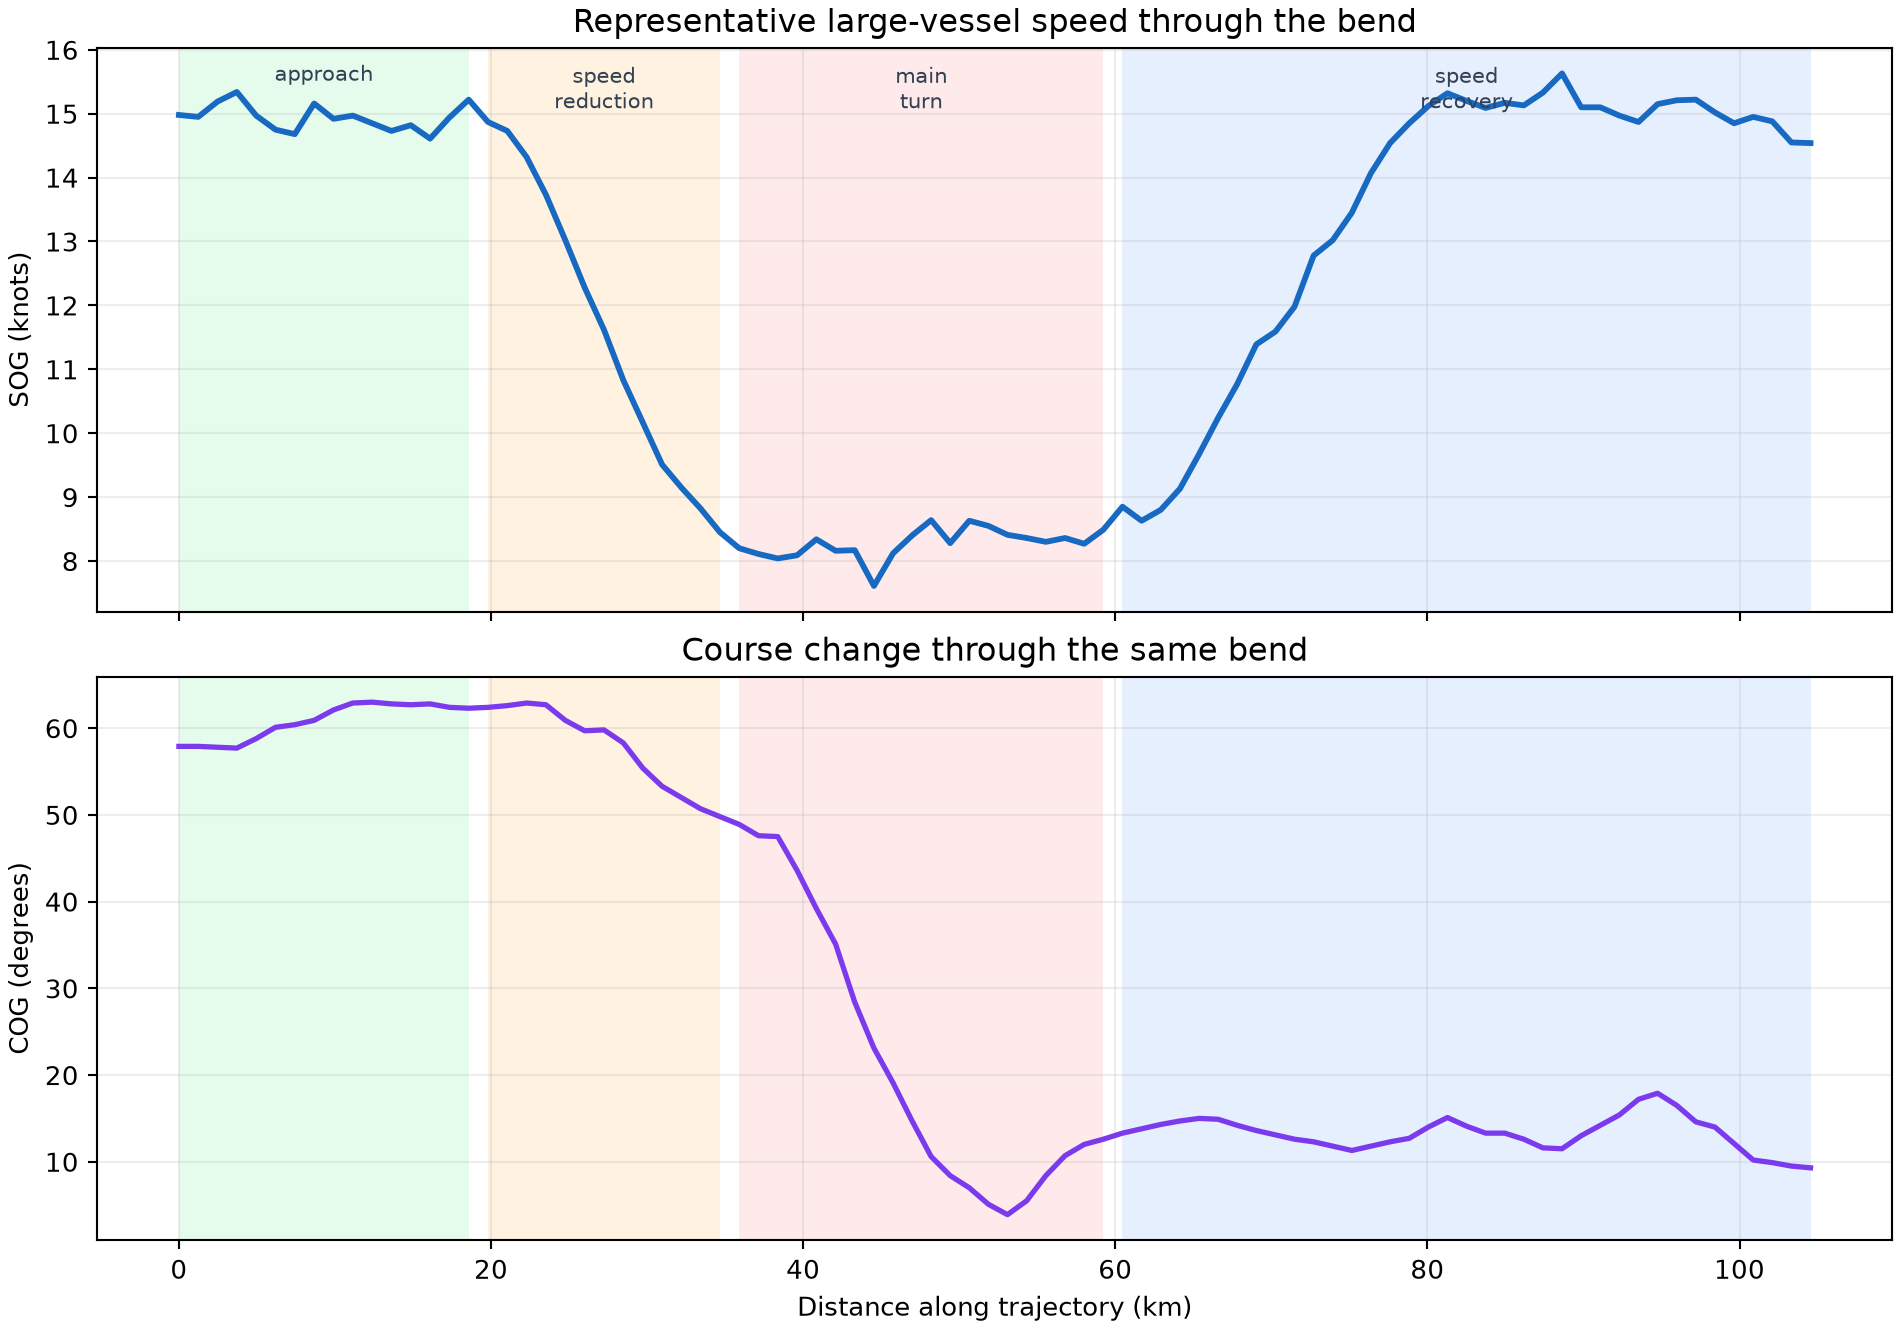

In [ ]:
import pandas as pd
df=pd.read_csv(dataset_path); print(df.groupby('movement_phase').sog_knots.describe())
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/bend_speed_dynamics.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Very High (6 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "bend_speed_phases",
  "insight": "Larger cargo and tanker vessels typically reduce speed before the main turn, remain slower through the strongest directional change, and gradually recover speed after leaving the bend.",
  "insight_value": {
    "median_phase_speed_knots": {
      "speed_approach": 12.27,
      "speed_speed recovery": 11.78,
      "speed_speed reduction": 10.05,
      "speed_main turn": 7.45
    }
  },
  "plot": {
    "plot_type": "phase_profile",
    "title": "Speed Dynamics through the Bend",
    "file": "visualizations/bend_speed_dynamics.png",
    "description": "Align vessel speed and COG change across approach, reduction, main-turn, and recovery phases."
  },
  "question": "How does speed change before, during, and after the main turn?",
  "actionable_insight": "Align vessel speed and COG change across approach, reduction, main-turn, and recovery phases.",
  "code": "import pandas as pd\ndf=pd.read_csv(dataset_path); print(df.groupby('movement_phase').sog_knots.describe())",
  "insight_type": "temporal_dynamics",
  "difficulty_level": 6,
  "difficulty_label": "very high",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "ship_type",
    "vessel_length",
    "gps_position",
    "course_over_ground",
    "point_speed",
    "vessel_id"
  ]
}

### **Question 3**: How is vessel draught associated with turning-path consistency?

#### Analysis action

Compare continuous draught with deviation from the independent deep-water route while retaining non-deterministic path choices.

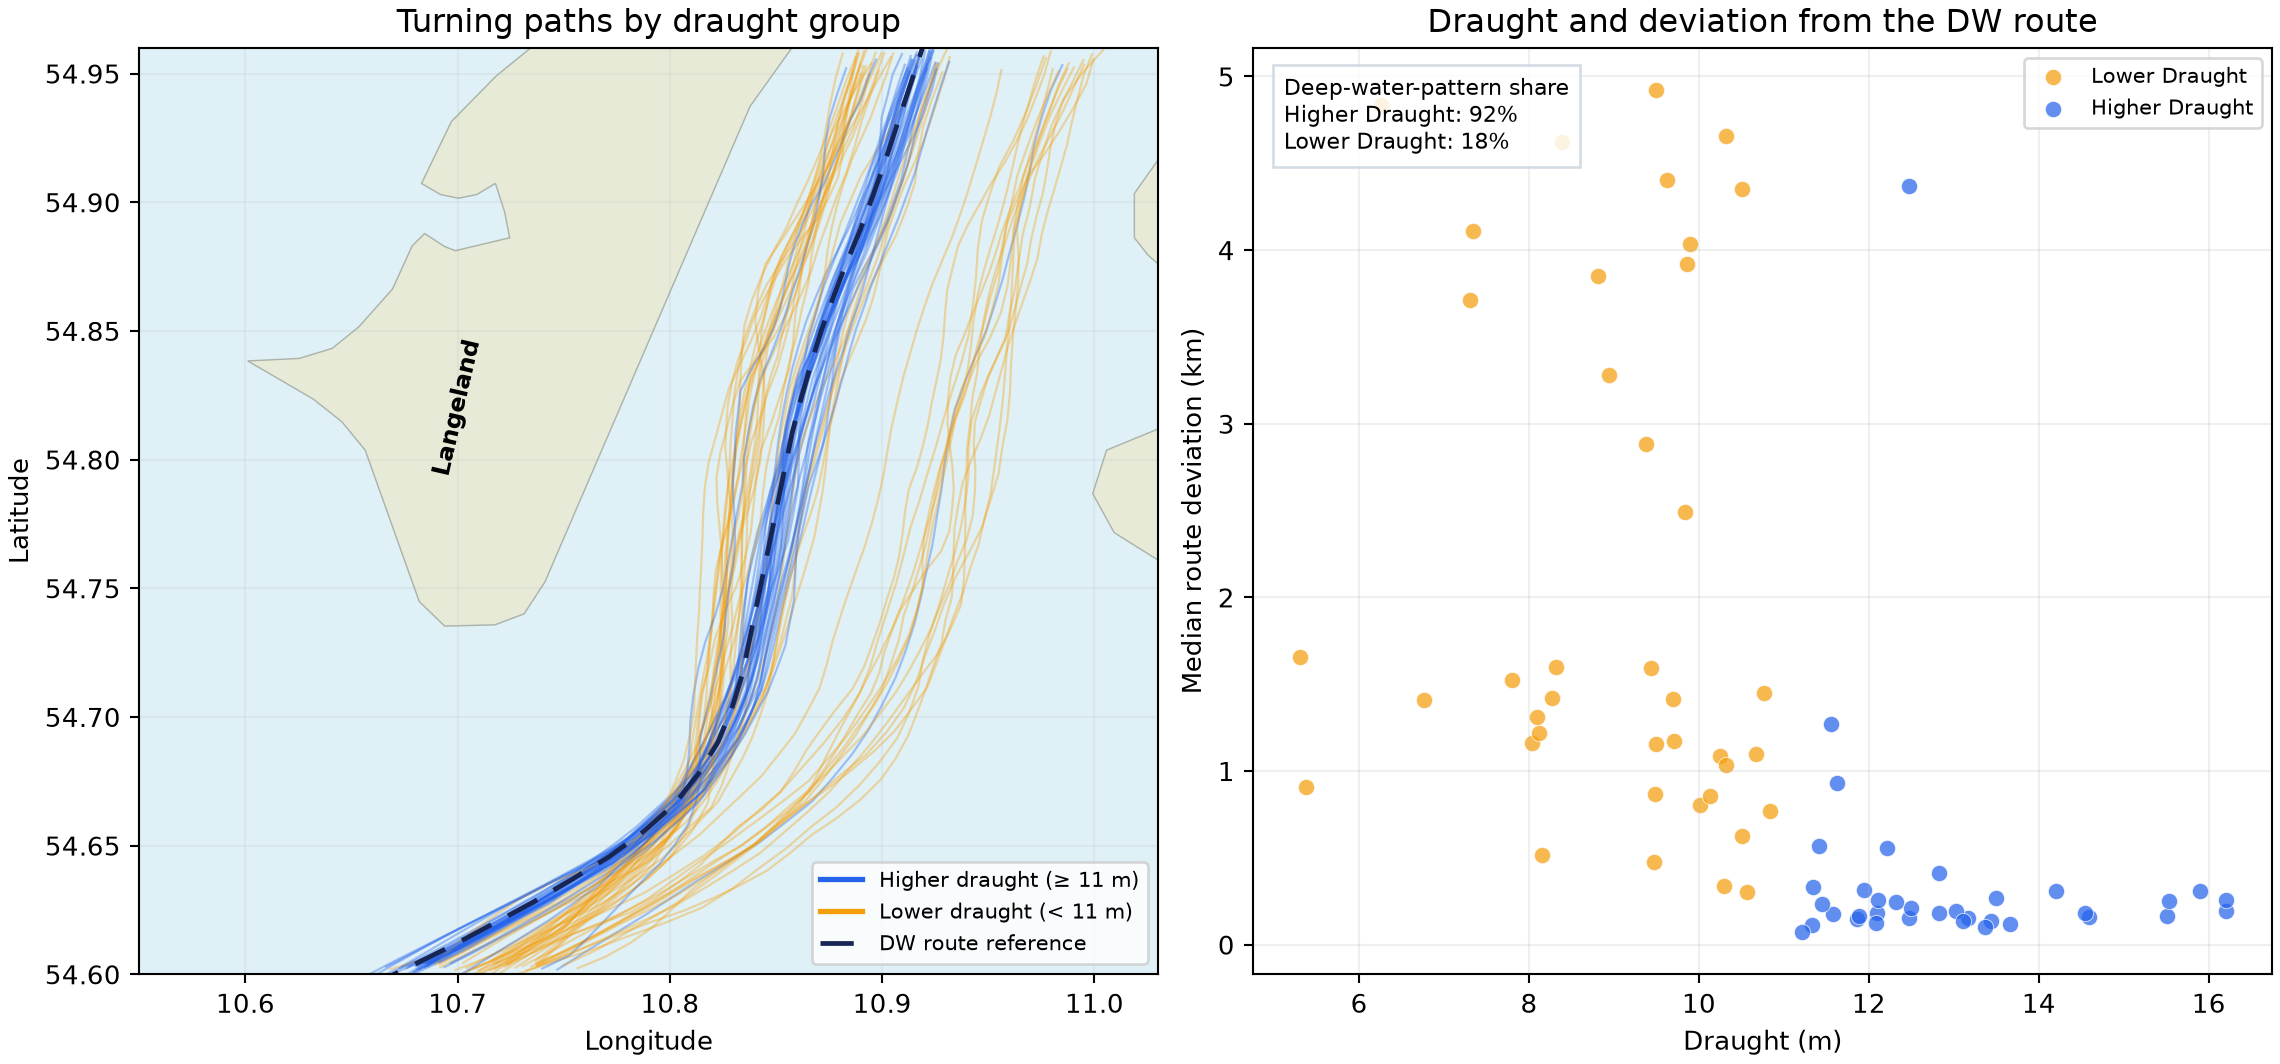

In [ ]:
import pandas as pd, numpy as np
df=pd.read_csv(dataset_path); vessels=pd.read_csv(user_dataset_path); trips=df[['trajectory_id','vessel_id','turning_pattern']].drop_duplicates().merge(vessels,on='vessel_id'); trips['draught_group']=np.where(trips.draught_m>=11,'higher draught','lower draught'); print(trips.groupby('draught_group').turning_pattern.value_counts())
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/draught_turning_consistency.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Medium (4 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "draught_path_consistency",
  "insight": "Higher-draught vessels are more likely to follow the more consistent deep-water turning pattern, while lower-draught vessels occupy a broader range of turning paths.",
  "insight_value": {
    "deep_water_pattern_share": {
      "higher draught": 0.917,
      "lower draught": 0.175
    },
    "median_deep_route_deviation_km": {
      "higher draught": 0.19,
      "lower draught": 1.42
    },
    "lower_draught_trajectories_between_2_and_4_km": 6
  },
  "plot": {
    "plot_type": "factor_scatter_and_share",
    "title": "Draught and Turning-path Consistency",
    "file": "visualizations/draught_turning_consistency.png",
    "description": "Compare continuous draught with deviation from the independent deep-water route while retaining non-deterministic path choices."
  },
  "question": "How is vessel draught associated with turning-path consistency?",
  "actionable_insight": "Compare continuous draught with deviation from the independent deep-water route while retaining non-deterministic path choices.",
  "code": "import pandas as pd, numpy as np\ndf=pd.read_csv(dataset_path); vessels=pd.read_csv(user_dataset_path); trips=df[['trajectory_id','vessel_id','turning_pattern']].drop_duplicates().merge(vessels,on='vessel_id'); trips['draught_group']=np.where(trips.draught_m>=11,'higher draught','lower draught'); print(trips.groupby('draught_group').turning_pattern.value_counts())",
  "insight_type": "factor_relationship",
  "difficulty_level": 4,
  "difficulty_label": "medium",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "draught",
    "gps_position",
    "route_reference",
    "vessel_id"
  ]
}

### Summary of Findings (Flag 25)

Traffic around southern Langeland forms three recurring manoeuvring patterns: an earlier tighter inshore turn, a consistent medium-radius DW-route turn, and a later wider turn on the Route H side. Larger cargo and tanker vessels typically reduce speed before the main turn, remain slower through the strongest directional change, and gradually recover speed after leaving the bend. Higher-draught vessels are more likely to follow the more consistent deep-water turning pattern, while lower-draught vessels occupy a broader range of turning paths.